# Three-level transmon fit of the qubit power sweep

Fits the 5.58 GHz fine power sweep, normalized by the no-qubit reference trace, with a
two-level and a three-level transmon scattering model, and reads off the line attenuation
from the VNA port to the qubit. The model code is in `fit_levels.py` (same folder).

## Model

**Hamiltonian** in the frame rotating at the drive frequency $\omega$ (Duffing transmon, levels $n = 0 \dots N_L-1$):

$$H/\hbar = \sum_n \Big[n\Delta + \tfrac{\alpha}{2}\,n(n-1)\Big]|n\rangle\langle n| + \tfrac{\Omega}{2}\,(b + b^\dagger),
\qquad \Delta = \omega_{01} - \omega,\quad b = \sum_n \sqrt{n}\,|n-1\rangle\langle n|$$

* $N_L = 2$: the usual two-level atom.
* $N_L = 3$: adds $|2\rangle$, i.e. the two-photon $0\to2$ resonance at $\omega_{01} + \alpha/2$ and the $1\to2$ transition at $\omega_{01} + \alpha$.

**Damping:** $\dot\rho = -i[H/\hbar, \rho] + \Gamma_1 D[b]\rho$ with $\Gamma_1 = 2\gamma_2$ (no pure dephasing). The steady state $\rho_{ss}$ is solved numerically.

**Transmission** (input–output): $t = 1 - i\,(\Gamma_r/\Omega)\,\langle b\rangle_{ss}$ with $\Gamma_r = \Gamma_1$, complex conjugated for the VNA convention.
For $N_L = 2$ this is the closed form $t = 1 - (1 - ix)/(1 + x^2 + s)$, $x = \Delta/\gamma_2$.

**Measured data**, trace $j$ at VNA power $P_j$:

$$S_{21,j}(f)\,/\,S_{21,\mathrm{ref}}(f) = A_j\,\big[1 - K\,(1 - t(f; P_j))\big]$$

* $K = |K|e^{i\varphi}$: impedance mismatch around the qubit (Fano phase).
* $A_j$: complex scale per trace, solved in closed form at every step.

**Fit parameters:** $f_{01}$, $\alpha$ (3-level only), $\gamma_2$, $|K|$, $\arg K$, and $k$ in $s = \Omega^2/(\Gamma_1\gamma_2) = k\,P_\mathrm{VNA}$.

**Calibration:** $\Omega^2 = 2\Gamma_r P_\mathrm{in}/\hbar\omega$ gives $P_\mathrm{in}(s{=}1) = \hbar\omega\gamma_2/2$.
The attenuation is $P_\mathrm{VNA}(s{=}1) - P_\mathrm{in}(s{=}1)$ in dB.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import fit_levels as fl

SWEEP = "../qubit-power-sweep-5_58GHz_fine.json"
REF = "../no-qubit-ref.json"      # qubit flux bias off: qubit out of band, t_ref = 1
PMAX = -20.0                      # dBm, fit only powers up to this (see below)

f, P, Sn, sig = fl.load(SWEEP, REF)   # f in MHz, Sn = S21 / S21_ref
print(f"{len(P)} traces, {P.min():g} .. {P.max():g} dBm, {f[0]/1e3:.2f} - {f[-1]/1e3:.2f} GHz, {len(f)} points")

51 traces, -50 .. 0 dBm, 5.40 - 5.80 GHz, 401 points


## Fit

Both models are fitted to the traces with $P_\mathrm{VNA} \le -20$ dBm over the full band 5.40–5.80 GHz.
Above about −16 dBm the drive ($\Omega/2\pi \gtrsim |\alpha|/4$) populates levels above $|2\rangle$, which the three-level model leaves out.

In [2]:
fits = {NL: fl.fit(SWEEP, REF, NL, PMAX) for NL in (2, 3)}

rows = [("reduced chi2", "red_chi2", "{:.2f}"), ("f01 (MHz)", "f01_mhz", "{:.2f}"),
        ("alpha/2pi (MHz)", "alpha_mhz", "{:.1f}"), ("gamma2/2pi (MHz)", "gamma2_mhz", "{:.2f}"),
        ("|K|", "K_abs", "{:.3f}"), ("arg K (rad)", "K_arg", "{:.3f}"),
        ("s=1 at P_VNA (dBm)", "psat_vna_dbm", "{:.2f}"), ("P_in(s=1) (dBm)", "pin_sat_dbm", "{:.2f}"),
        ("attenuation (dB)", "attenuation_db", "{:.2f}")]
print(f"{'':22s}{'2-level':>12s}{'3-level':>12s}")
for label, key, fmt in rows:
    vals = [fmt.format(fits[n][key]) if fits[n][key] is not None else "-" for n in (2, 3)]
    print(f"{label:22s}{vals[0]:>12s}{vals[1]:>12s}")

                           2-level     3-level
reduced chi2                  2.09        1.48
f01 (MHz)                  5576.42     5576.65
alpha/2pi (MHz)                  -      -223.4
gamma2/2pi (MHz)             15.42       15.34
|K|                          1.016       1.024
arg K (rad)                  0.339       0.376
s=1 at P_VNA (dBm)          -25.18      -25.14
P_in(s=1) (dBm)            -127.47     -127.49
attenuation (dB)            102.29      102.36


## Experiment vs theory

$r = 1 - S_{21}/S_{21,\mathrm{ref}}$, shown with $\mathrm{Im}\,r > 0$ above resonance (same convention as `qubit_power_fit.py`).
Above the dashed line the theory is a prediction: those traces were not fitted.

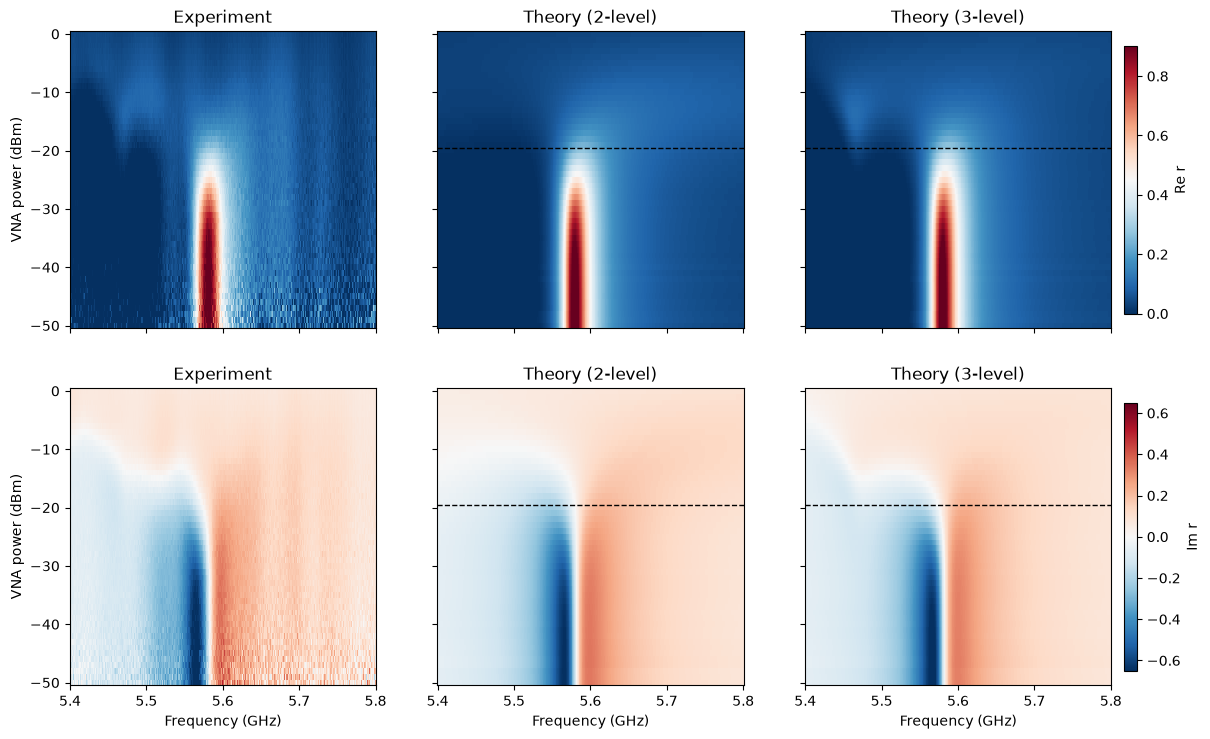

In [3]:
def model_r(fit):
    m = fl.model_traces(np.array(fit["x"]), fl.Transmon(fit["NL"]), f, P)
    _, scaled = fl.project(m, Sn)
    return np.conj(1 - np.array(scaled))

r_data = np.conj(1 - Sn)
cols = [(r_data, "Experiment")] + [(model_r(fits[n]), f"Theory ({n}-level)") for n in (2, 3)]

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), sharex=True, sharey=True)
for row, (take, label) in enumerate(((np.real, "Re r"), (np.imag, "Im r"))):
    lim = np.percentile(np.abs(take(r_data)), 99.5)
    for col, (z, title) in enumerate(cols):
        ax = axes[row, col]
        im = ax.pcolormesh(f/1e3, P, take(z), shading="nearest", cmap="RdBu_r",
                           vmin=0 if row == 0 else -lim, vmax=lim)
        ax.set_title(title)
        if col > 0:
            ax.axhline(PMAX + 0.5, color="k", ls="--", lw=1)
    fig.colorbar(im, ax=axes[row, :].tolist(), label=label, shrink=0.9, pad=0.01)
for ax in axes[-1]: ax.set_xlabel("Frequency (GHz)")
for ax in axes[:, 0]: ax.set_ylabel("VNA power (dBm)")
plt.show()

## Line cuts

The dip at 5.468 GHz ($\omega_{01} + \alpha/2$) that appears around −20 to −10 dBm is the two-photon $0\to2$ resonance.
Only the three-level model has it.

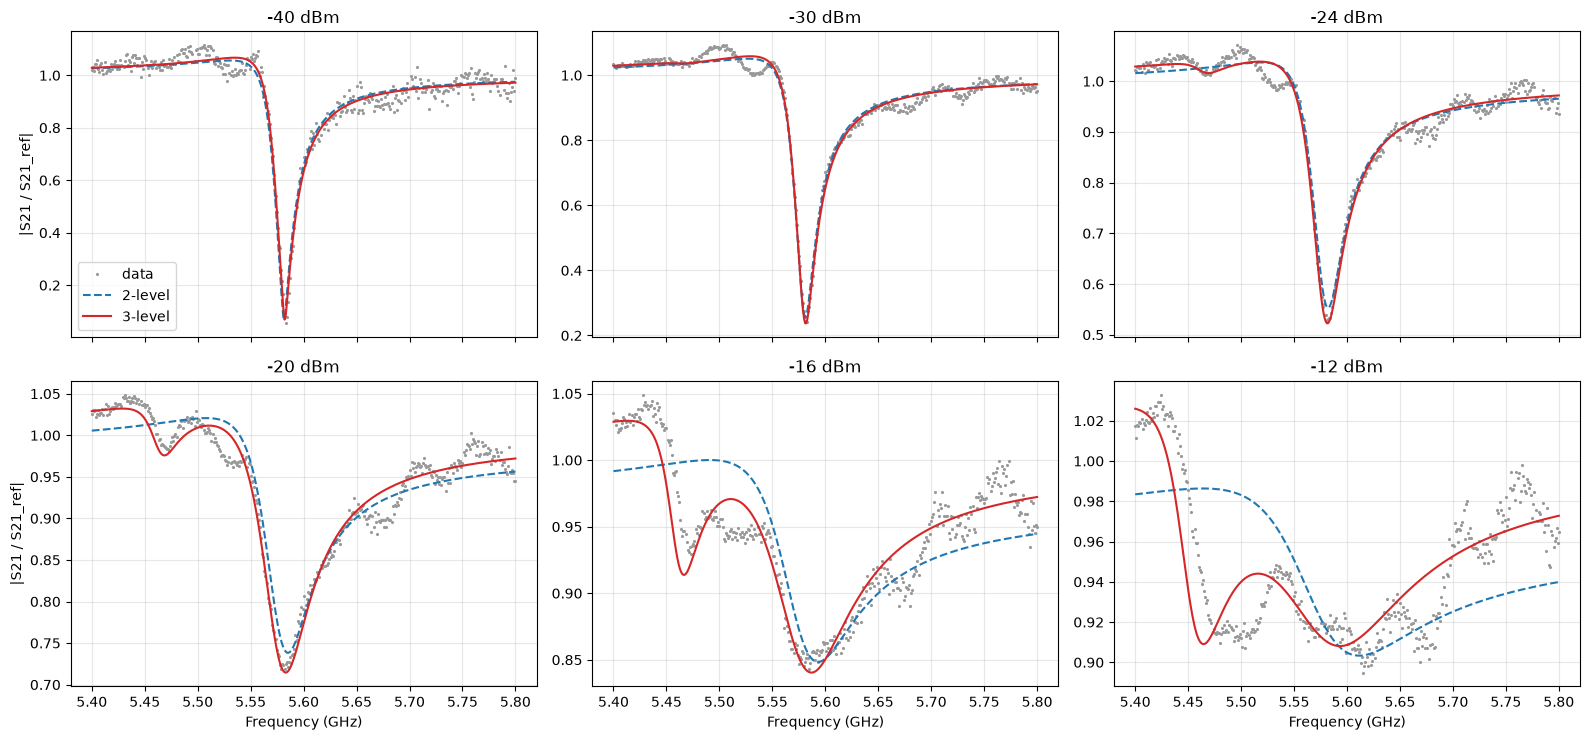

In [4]:
curves = {n: fl.project(fl.model_traces(np.array(fits[n]["x"]), fl.Transmon(n), f, P), Sn) for n in (2, 3)}
A3 = curves[3][0]

fig, axs = plt.subplots(2, 3, figsize=(16, 7.5), sharex=True)
for ax, pw in zip(axs.flat, (-40, -30, -24, -20, -16, -12)):
    i = int(np.where(P == pw)[0][0])
    ax.plot(f/1e3, np.abs(Sn[i]/A3[i]), ".", ms=2.5, c="0.6", label="data")
    ax.plot(f/1e3, np.abs(curves[2][1][i]/A3[i]), "--", c="C0", label="2-level")
    ax.plot(f/1e3, np.abs(curves[3][1][i]/A3[i]), "-", c="C3", label="3-level")
    ax.set_title(f"{pw} dBm")
    ax.grid(alpha=.3)
axs[0, 0].legend()
for ax in axs[1]: ax.set_xlabel("Frequency (GHz)")
for ax in axs[:, 0]: ax.set_ylabel("|S21 / S21_ref|")
plt.tight_layout(); plt.show()

## Why not fit all powers?

The same fits over all powers (up to 0 dBm) give these attenuations:

In [5]:
for n in (2, 3):
    a = fl.fit(SWEEP, REF, n, 0.0)
    print(f"{n}-level, all powers: attenuation {a['attenuation_db']:.2f} dB, reduced chi2 {a['red_chi2']:.2f}")

2-level, all powers: attenuation 99.77 dB, reduced chi2 13.02


3-level, all powers: attenuation 102.25 dB, reduced chi2 5.83


## Summary

* Up to −20 dBm the two models give the same attenuation, about **102.3 dB** from the VNA port to the qubit. This includes the 25 dB warm programmable attenuator.
* The three-level model fits better, and it predicts the two-photon branch above −20 dBm. It gives $\alpha/2\pi \approx -223$ MHz.
* Fitting all powers biases the two-level result by about 2.5 dB. The three-level all-power fit stays near 102.3 dB, but above −10 dBm it misses the data, so do not rely on it.
* Main assumptions:
  * no non-radiative decay or pure dephasing ($\Gamma_r = \Gamma_1 = 2\gamma_2$);
  * $K$ independent of frequency;
  * an accurate VNA output power.